# 01 - Data exploration

What the storage valuation is built on:

1. **TTF front-month history** (Yahoo Finance `TTF=F`, EUR/MWh): level, volatility regimes, seasonality.
   It feeds the calibration of the one-factor price model in notebook 02.
2. **Forward curve** $F(0,T)$: the input of the intrinsic and LSMC valuations. No free source provides
   a full monthly TTF curve, so the default run uses a clearly labelled **synthetic** curve; a
   hand-typed ICE Endex / EEX settlement curve can be dropped in as a CSV.
3. **GIE AGSI+ storage levels** (NL, DE, FR): the physical fill cycle the optimal policy should resemble.

Sources, licences and download instructions: `data/README.md`. All logic lives in `gasstorage.data`.

In [1]:
import datetime as dt
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# run from the repository root so that data/ and reports/ paths resolve
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.data import agsi
from gasstorage.data.forward_curve import ForwardCurve
from gasstorage.data.ttf import get_ttf_history

plotting.apply_style()
cfg = load_config("configs/storage_default.yaml")

## 1. TTF front-month history

In [2]:
ttf = get_ttf_history()  # cached in data/raw/ttf_front_month.csv after the first download
print(f"{len(ttf)} daily closes, {ttf.index.min().date()} -> {ttf.index.max().date()}")
ttf.describe().round(2)

2283 daily closes, 2017-10-23 -> 2026-11-18


count    2283.00
mean       43.25
std        40.95
min         3.51
25%        18.79
50%        31.94
75%        47.48
max       339.20
Name: price_eur_mwh, dtype: float64

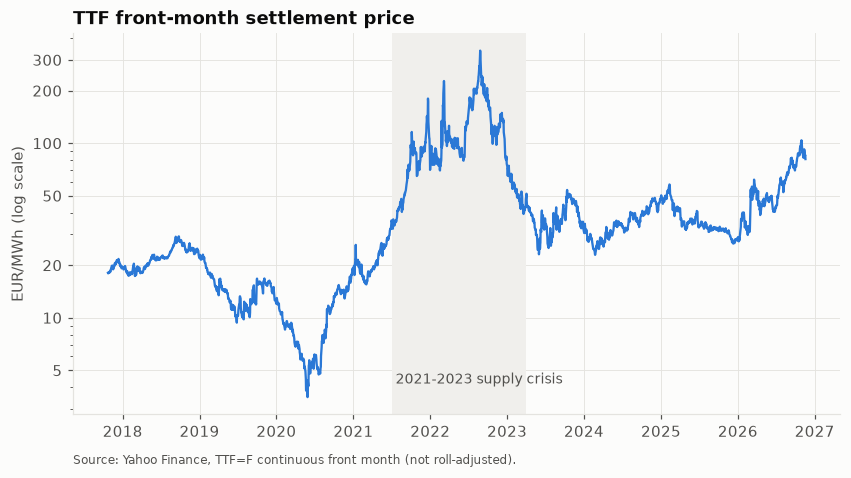

In [3]:
fig, ax = plt.subplots()
crisis = (pd.Timestamp("2021-07-01"), pd.Timestamp("2023-03-31"))
ax.axvspan(*crisis, color=plotting.NEUTRAL_FILL, lw=0)
ax.text(crisis[0], 4.2, " 2021-2023 supply crisis", color=plotting.TEXT_SECONDARY, fontsize=9)
ax.plot(ttf.index, ttf.to_numpy(), color=plotting.SERIES[0])
ax.set_yscale("log")
ticks = [5, 10, 20, 50, 100, 200, 300]
ax.set_yticks(ticks, labels=[str(t) for t in ticks])
ax.set_ylabel("EUR/MWh (log scale)")
ax.set_title("TTF front-month settlement price")
ax.text(
    0,
    -0.13,
    "Source: Yahoo Finance, TTF=F continuous front month (not roll-adjusted).",
    transform=ax.transAxes,
    fontsize=8,
    color=plotting.TEXT_SECONDARY,
)
plotting.save_figure(fig, "01_ttf_history")
fig

**Volatility regimes.** Annualised volatility of daily log-returns,
$\hat\sigma_{\text{ann}} = \sqrt{252}\,\operatorname{std}(\ln S_{t+1} - \ln S_t)$, by calendar year.
Roll jumps of the continuous contract are included, so these are slight over-estimates.

In [4]:
log_ret = np.log(ttf).diff().dropna()
years = ttf.groupby(ttf.index.year)
by_year = pd.DataFrame(
    {
        "n_obs": years.size(),
        "mean_price": years.mean(),
        "min_price": years.min(),
        "max_price": years.max(),
        "ann_vol_log_ret": log_ret.groupby(log_ret.index.year).std() * np.sqrt(252),
    }
)
by_year.round(2)

,n_obs,mean_price,min_price,max_price,ann_vol_log_ret
date,,,,,
2017,48,19.75,17.96,21.73,0.30
2018,251,22.26,17.35,29.25,0.34
2019,252,14.60,9.38,23.00,0.69
2020,253,9.61,3.51,19.15,0.73
2021,252,47.65,15.52,180.27,0.94
2022,251,133.34,69.79,339.20,1.33
2023,251,41.30,23.10,74.30,0.98
2024,251,34.65,22.93,48.89,0.49
2025,252,36.23,26.60,58.04,0.42


**Seasonality.** For each calendar month, the average deviation of the log-price from its
own calendar-year mean, $\overline{\ln S_t - \overline{\ln S}_{\text{year}(t)}}$, computed
separately before and after the crisis. This removes the level shifts between years and
isolates the within-year shape that the seasonal component of notebook 02 has to capture.
Partial calendar years (2017, 2026) are excluded.

In [5]:
log_p = np.log(ttf)
dev = log_p - log_p.groupby(log_p.index.year).transform("mean")
windows = {"2018-2020": ("2018-01-01", "2020-12-31"), "2023-2025": ("2023-01-01", "2025-12-31")}
season = pd.DataFrame(
    {
        name: dev.loc[a:b].groupby(dev.loc[a:b].index.month).mean()
        for name, (a, b) in windows.items()
    }
)
season.index.name = "month"
season.round(3)

,2018-2020,2023-2025
month,,
1,0.159,0.206
2,0.028,0.105
3,-0.049,0.010
4,-0.127,-0.048
5,-0.220,-0.107
6,-0.272,-0.069
7,-0.260,-0.133
8,-0.077,-0.038
9,0.134,-0.042


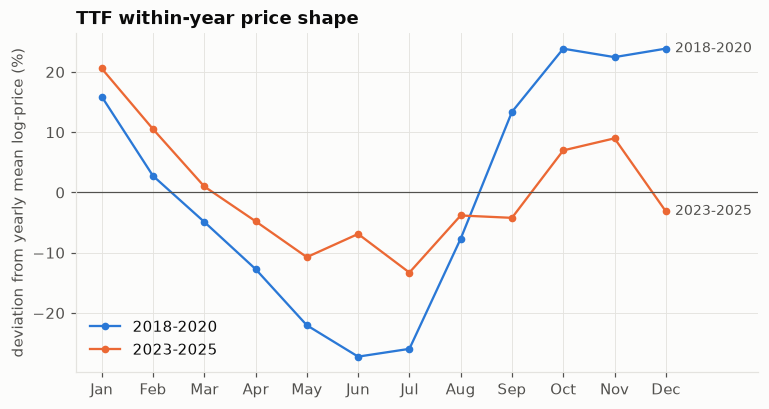

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for color, col in zip(plotting.SERIES, season.columns, strict=False):
    ax.plot(season.index, 100 * season[col], marker="o", ms=4, color=color, label=col)
    ax.annotate(
        col,
        (12, 100 * season[col].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=plotting.TEXT_SECONDARY,
    )
ax.axhline(0, color=plotting.TEXT_SECONDARY, lw=0.8)
ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(0.5, 13.8)
ax.set_ylabel("deviation from yearly mean log-price (%)")
ax.set_title("TTF within-year price shape")
ax.legend(loc="lower left")
plotting.save_figure(fig, "01_ttf_seasonality")
fig

## 2. Forward curve

The valuation needs $F(0,T)$ for every delivery month of the storage year (April to March). The default
configuration uses the **synthetic** generator
$F_m = L + A\cos\big(2\pi(\text{month}(m)-1)/12\big) + c\,k_m/12$ (winter peak, summer trough, contango).
Its parameters are not calibrated to any market quote. To value on a real curve, save settlement prices
as `delivery_month,price` in `data/raw/ttf_forward_curve.csv` and set `market.forward_curve.source: csv`.

In [7]:
c = cfg.contract
curve = ForwardCurve.from_config(cfg.market.forward_curve, c.start_date, c.end_date)
print(curve.source)
curve.to_frame().set_index("delivery_month").T.round(2)

SYNTHETIC (L=30.0, A=5.0, c=1.0)


delivery_month,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,2026-12,2027-01,2027-02,2027-03
price,30.0,27.58,25.84,25.25,26.0,27.92,30.5,33.08,35.0,35.75,35.16,33.42


winter-summer spread (max - min monthly price): 10.50 EUR/MWh


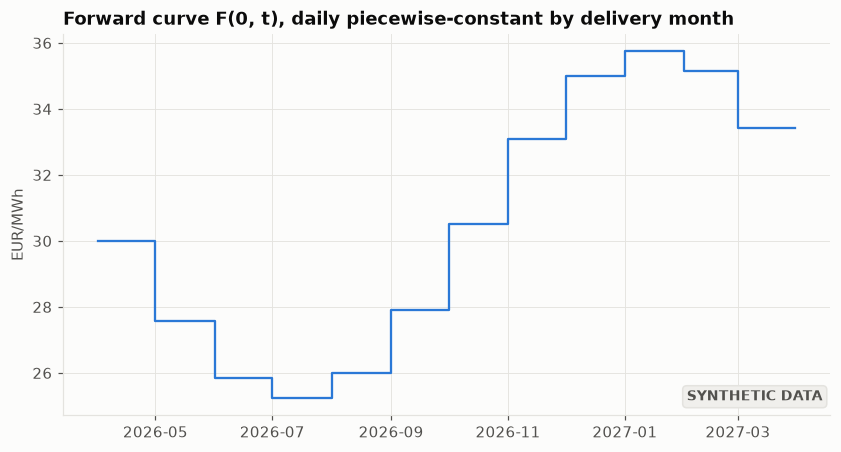

In [8]:
days = pd.date_range(c.start_date, c.end_date, freq="D")
fig, ax = plt.subplots()
ax.step(days, curve.daily(days), where="post", color=plotting.SERIES[0])
ax.set_ylabel("EUR/MWh")
ax.set_title("Forward curve F(0, t), daily piecewise-constant by delivery month")
if curve.is_synthetic:
    plotting.mark_synthetic(ax, corner="lower right")
spread = curve.prices.max() - curve.prices.min()
print(f"winter-summer spread (max - min monthly price): {spread:.2f} EUR/MWh")
plotting.save_figure(fig, "01_forward_curve")
fig

## 3. GIE AGSI+ storage levels (NL, DE, FR)

Requires a free API key in the `AGSI_API_KEY` environment variable (or cached CSVs in `data/raw/`).
Source: GIE AGSI+, https://agsi.gie.eu.

In [9]:
countries = ["NL", "DE", "FR"]
try:
    levels = agsi.add_storage_year(
        agsi.load_storage_levels(countries, dt.date(2017, 4, 1), dt.date.today())
    )
except agsi.AGSIKeyMissingError as err:
    levels = None
    print(err)

No AGSI+ API key found. Register for free at https://agsi.gie.eu/account, copy the key from your account page and set the AGSI_API_KEY environment variable. Cached CSVs in data/raw/ can be used without a key.


In [10]:
if levels is not None:
    last_years = sorted(levels["storage_year"].unique())[-2:]
    fig, axes = plt.subplots(1, len(countries), figsize=(12, 3.8), sharey=True)
    for ax, country in zip(axes, countries, strict=True):
        sub = levels[levels["country"] == country]
        for year, grp in sub.groupby("storage_year"):
            highlight = year in last_years
            ax.plot(
                grp["day_of_storage_year"],
                grp["full_pct"],
                color=plotting.SERIES[last_years.index(year)] if highlight else "#c9c8c3",
                lw=1.5 if highlight else 0.8,
                label=f"{year}/{year + 1}" if highlight else None,
            )
        ax.set_title(country)
        ax.set_xticks([0, 91, 183, 275, 365], ["Apr", "Jul", "Oct", "Jan", "Apr"])
    axes[0].set_ylabel("storage fill (% of WGV)")
    axes[-1].legend(loc="lower center")
    fig.suptitle(
        "Storage fill by storage year (grey: earlier years). Source: GIE AGSI+", x=0.01, ha="left"
    )
    plotting.save_figure(fig, "01_agsi_fill")
    display(fig)
else:
    print("AGSI+ section skipped: no API key and no cached data.")

AGSI+ section skipped: no API key and no cached data.


## 4. Findings (data as of the last download, 2026-11-18)

* **Level.** 2,283 daily closes since 2017-10-23, from 3.51 EUR/MWh (2020) to 339.20 EUR/MWh (2022).
  The price level is not stationary across regimes, which is why the model works on the log-price
  *relative to the forward curve* rather than on a fixed long-run mean.
* **Volatility regimes.** Annualised log-return volatility is 0.30-0.49 in calm years (2017-2018,
  2024-2025), around 0.70 in 2019-2020, 0.94-1.33 during the 2021-2023 crisis and 0.81 in 2026
  year-to-date. The calibration window therefore drives $\sigma$ and, through it, the extrinsic value:
  notebook 02 calibrates on several windows instead of one.
* **Seasonality.** The front month is cheapest in early summer and most expensive in winter. The
  peak-to-trough amplitude of the log-price deviation is about 0.51 in 2018-2020 and 0.34 in
  2023-2025: the summer-winter spread that storage monetises has narrowed after the crisis.
  Caveat: on trade date $t$ the front month delivers in the *next* month, so this shape is shifted
  by about one month relative to delivery months.
* **Forward curve.** The default run uses the SYNTHETIC curve (winter-summer spread 10.50 EUR/MWh).
  A real curve must be typed in from ICE Endex / EEX settlements (see `data/README.md`).
* **AGSI+.** Skipped when no `AGSI_API_KEY` is set; the section runs unchanged once the key exists.